<a href="https://colab.research.google.com/github/QuantLet/CBDC/blob/main/CBDC%20vs.%20Stablecoin/CDBC%20vsStablecoins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import matplotlib.pyplot as plt
import numpy as np

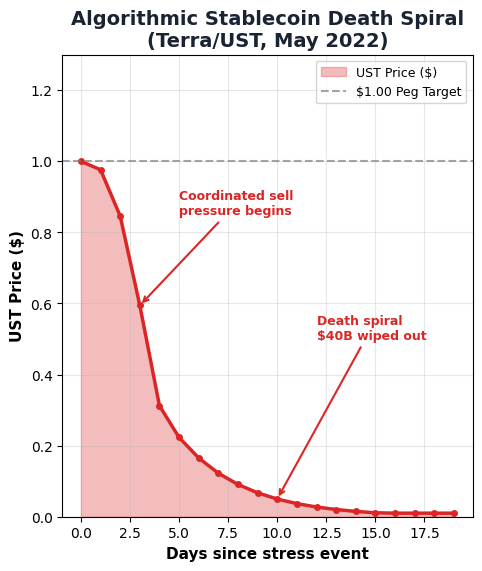

In [ ]:
# Algorithmic Death Spiral (Terra/UST)
fig = plt.figure(figsize=(18, 6))
fig.patch.set_alpha(0.0)

ax2 = fig.add_subplot(132)
ax2.patch.set_alpha(0.0)
days = np.arange(0, 20)
confidence = np.maximum(0, 1 - 0.08 * days**1.8)
ust_price = 1.0 * np.exp(-0.3 * (1 - confidence) * days)
ust_price = np.maximum(0.01, ust_price)

ax2.fill_between(days, ust_price, alpha=0.3, color='#dc2626', label='UST Price ($)')
ax2.plot(days, ust_price, color='#dc2626', linewidth=2.5, marker='o', markersize=4)
ax2.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='$1.00 Peg Target')

ax2.annotate('Coordinated sell\npressure begins', xy=(3, ust_price[3]), xytext=(5, 0.85),
            arrowprops=dict(arrowstyle='->', color='#dc2626', lw=1.5),
            fontsize=9, fontweight='bold', color='#dc2626')
ax2.annotate('Death spiral\n$40B wiped out', xy=(10, ust_price[10]), xytext=(12, 0.5),
            arrowprops=dict(arrowstyle='->', color='#dc2626', lw=1.5),
            fontsize=9, fontweight='bold', color='#dc2626')

ax2.set_xlabel('Days since stress event', fontsize=11, fontweight='bold')
ax2.set_ylabel('UST Price ($)', fontsize=11, fontweight='bold')
ax2.set_title('Algorithmic Stablecoin Death Spiral\n(Terra/UST, May 2022)', size=14, fontweight='bold', color='#1a2332')
ax2.set_ylim(0, 1.3)
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

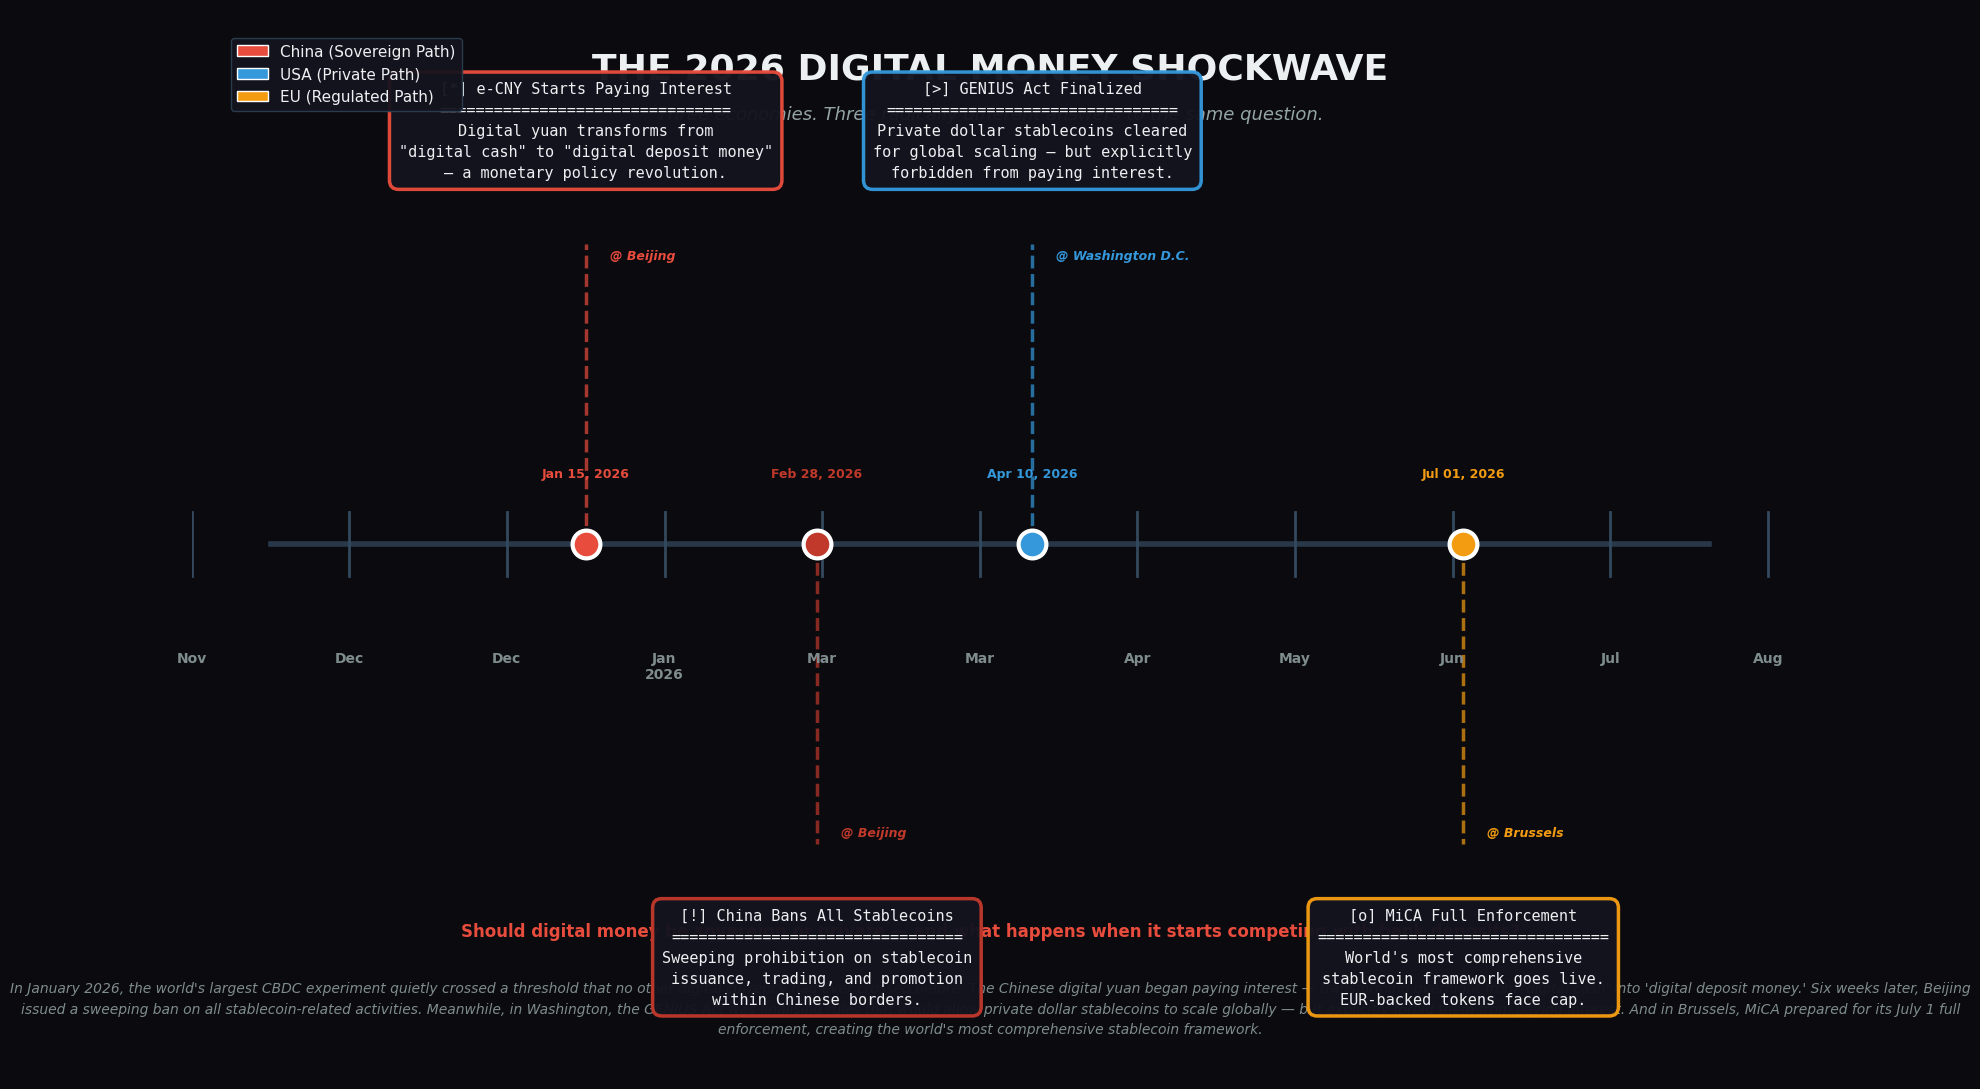

Timeline saved successfully!


In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np
from datetime import datetime, timedelta

# Set up the figure with a dark, dramatic background
fig, ax = plt.subplots(figsize=(20, 11), facecolor='#0a0a0f')
ax.set_facecolor('#0a0a0f')

# Timeline parameters
start_date = datetime(2025, 11, 1)
end_date = datetime(2026, 9, 1)

# Define events
events = [
    {
        'date': datetime(2026, 1, 15),
        'title': 'e-CNY Starts Paying Interest',
        'location': 'Beijing',
        'description': 'Digital yuan transforms from\n"digital cash" to "digital deposit money"\n— a monetary policy revolution.',
        'color': '#e74c3c',
        'y_offset': 0.78,
        'icon': '*'
    },
    {
        'date': datetime(2026, 2, 28),
        'title': 'China Bans All Stablecoins',
        'location': 'Beijing',
        'description': 'Sweeping prohibition on stablecoin\nissuance, trading, and promotion\nwithin Chinese borders.',
        'color': '#c0392b',
        'y_offset': 0.22,
        'icon': '!'
    },
    {
        'date': datetime(2026, 4, 10),
        'title': 'GENIUS Act Finalized',
        'location': 'Washington D.C.',
        'description': 'Private dollar stablecoins cleared\nfor global scaling — but explicitly\nforbidden from paying interest.',
        'color': '#3498db',
        'y_offset': 0.78,
        'icon': '>'
    },
    {
        'date': datetime(2026, 7, 1),
        'title': 'MiCA Full Enforcement',
        'location': 'Brussels',
        'description': "World's most comprehensive\nstablecoin framework goes live.\nEUR-backed tokens face cap.",
        'color': '#f39c12',
        'y_offset': 0.22,
        'icon': 'o'
    }
]

# Draw the main timeline axis
ax.axhline(y=0.5, xmin=0.05, xmax=0.95, color='#2c3e50', linewidth=4, alpha=0.9, zorder=1)

# Add month markers on the timeline
months = []
current = start_date
while current <= end_date:
    months.append(current)
    x_pos = (current - start_date).days / (end_date - start_date).days
    ax.plot([x_pos, x_pos], [0.47, 0.53], color='#34495e', linewidth=2, zorder=2)
    month_label = current.strftime('%b\n%Y') if current.month == 1 else current.strftime('%b')
    ax.text(x_pos, 0.40, month_label, ha='center', va='top', fontsize=10,
            color='#7f8c8d', fontweight='bold', zorder=3)
    current += timedelta(days=30)

# Plot each event
for event in events:
    x_pos = (event['date'] - start_date).days / (end_date - start_date).days
    y_pos = event['y_offset']

    # Draw connection line from timeline to event box
    ax.plot([x_pos, x_pos], [0.5, y_pos], color=event['color'], linewidth=2.5,
            linestyle='--', alpha=0.7, zorder=2)

    # Draw the event node on timeline
    ax.scatter(x_pos, 0.5, s=400, c=event['color'], edgecolors='white',
               linewidths=3, zorder=5, marker='o')

    # Event box
    box_color = event['color']
    bbox_props = dict(boxstyle="round,pad=0.6", facecolor='#14141f',
                      edgecolor=box_color, linewidth=2.5, alpha=0.97)

    # Build text
    text_content = f"[{event['icon']}] {event['title']}\n"
    text_content += f"{'=' * 32}\n"
    text_content += f"{event['description']}"

    # Place text
    va_align = 'bottom' if y_pos > 0.5 else 'top'
    text_y = y_pos + 0.06 if y_pos > 0.5 else y_pos - 0.06

    ax.text(x_pos, text_y, text_content, ha='center', va=va_align,
            fontsize=11, color='#ecf0f1', fontweight='normal',
            bbox=bbox_props, zorder=4, linespacing=1.5,
            family='monospace')

    # Location label
    loc_y = y_pos - 0.01 if y_pos > 0.5 else y_pos + 0.01
    ax.text(x_pos + 0.015, loc_y, f"@ {event['location']}", ha='left', va='center',
            fontsize=9, color=box_color, fontweight='bold',
            style='italic', zorder=6)

    # Date label near timeline
    date_str = event['date'].strftime('%b %d, %Y')
    ax.text(x_pos, 0.56, date_str, ha='center', va='bottom',
            fontsize=9, color=event['color'], fontweight='bold', zorder=6)

# Title
ax.text(0.5, 0.96, 'THE 2026 DIGITAL MONEY SHOCKWAVE',
        ha='center', va='top', fontsize=26, color='#ecf0f1',
        fontweight='bold', transform=ax.transAxes, family='sans-serif')

ax.text(0.5, 0.91, 'Three economies. Three radically different answers to the same question.',
        ha='center', va='top', fontsize=13, color='#95a5a6',
        style='italic', transform=ax.transAxes)

# Bottom narrative
narrative = (
    "In January 2026, the world's largest CBDC experiment quietly crossed a threshold that no other "
    "digital currency had ever crossed before. The Chinese digital yuan began paying interest — "
    "transforming overnight from 'digital cash' into 'digital deposit money.' Six weeks later, "
    "Beijing issued a sweeping ban on all stablecoin-related activities. Meanwhile, in Washington, "
    "the GENIUS Act was finalising rules that would allow private dollar stablecoins to scale globally — "
    "but explicitly forbid them from paying interest. And in Brussels, MiCA prepared for its July 1 "
    "full enforcement, creating the world's most comprehensive stablecoin framework."
)

ax.text(0.5, 0.04, narrative, ha='center', va='bottom', fontsize=10,
        color='#7f8c8d', transform=ax.transAxes, wrap=True,
        linespacing=1.6, style='italic')

# The central question
ax.text(0.5, 0.13, 'Should digital money be sovereign or private — and what happens when it starts competing with bank deposits?',
        ha='center', va='bottom', fontsize=12, color='#e74c3c',
        fontweight='bold', transform=ax.transAxes, wrap=True)

# Legend
legend_elements = [
    mpatches.Patch(facecolor='#e74c3c', edgecolor='white', label='China (Sovereign Path)'),
    mpatches.Patch(facecolor='#3498db', edgecolor='white', label='USA (Private Path)'),
    mpatches.Patch(facecolor='#f39c12', edgecolor='white', label='EU (Regulated Path)')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=11,
          facecolor='#14141f', edgecolor='#2c3e50', labelcolor='#ecf0f1',
          framealpha=0.95, bbox_to_anchor=(0.02, 0.98))

# Clean up axes
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

plt.tight_layout()

plt.show()
print("Timeline saved successfully!")


Risk Score Model

In [ ]:
"""
Sovereign Digital Money vs. Private Stablecoins
Risk Scoring Engine
"""

from dataclasses import dataclass
from enum import Enum
from typing import Optional

class AssetType(Enum):
    CBDC = "cbdc"
    FIAT_BACKED_STABLECOIN = "fiat_stablecoin"
    CRYPTO_BACKED_STABLECOIN = "crypto_stablecoin"
    ALGORITHMIC_STABLECOIN = "algo_stablecoin"

@dataclass
class DigitalMoneyAsset:
    name: str
    asset_type: AssetType
    # Reserve & solvency (0-10, 10 = best)
    reserve_transparency: float      # Audit frequency, attestation quality
    reserve_quality: float           # T-bills vs commercial paper vs crypto
    issuer_solvency: float           # Capital buffers, regulatory oversight

    # Technical & operational (0-10)
    smart_contract_risk: float       # 10 = formally verified / no code
    custody_risk: float              # 10 = self-custody possible / insured
    oracle_dependency: float         # 10 = no price oracle needed (CBDC)

    # Market & liquidity (0-10)
    secondary_liquidity: float     # Depth on DEXs/CEXs
    redemption_reliability: float  # Historical 1:1 peg maintenance
    fx_volatility: float           # 10 = pegged perfectly

    # Regulatory & systemic (0-10)
    regulatory_clarity: float      # Legal status certainty
    systemic_backstop: float        # 10 = central bank lender of last resort
    sanctions_resilience: float    # 10 = censorship resistant OR legally compliant

    # Optional overrides
    historical_depeg_severity: Optional[float] = None  # Max % deviation

class RiskScorer:
    WEIGHTS = {
        'solvency': 0.25,
        'technical': 0.20,
        'market': 0.25,
        'regulatory': 0.20,
        'systemic': 0.10
    }

    def score(self, asset: DigitalMoneyAsset) -> dict:
        # Component scores (0-10, higher = safer)
        solvency = (asset.reserve_transparency +
                   asset.reserve_quality +
                   asset.issuer_solvency) / 3

        technical = (asset.smart_contract_risk +
                    asset.custody_risk +
                    asset.oracle_dependency) / 3

        market = (asset.secondary_liquidity +
                 asset.redemption_reliability +
                 asset.fx_volatility) / 3

        regulatory = asset.regulatory_clarity

        systemic = (asset.systemic_backstop +
                   asset.sanctions_resilience) / 2

        # Weighted composite (0-10)
        composite = (
            solvency * self.WEIGHTS['solvency'] +
            technical * self.WEIGHTS['technical'] +
            market * self.WEIGHTS['market'] +
            regulatory * self.WEIGHTS['regulatory'] +
            systemic * self.WEIGHTS['systemic']
        )

        # Convert to risk score (0-100, lower = safer) for display
        risk_score = (10 - composite) * 10

        return {
            'asset': asset.name,
            'type': asset.asset_type.value,
            'component_scores': {
                'solvency': round(solvency, 2),
                'technical': round(technical, 2),
                'market': round(market, 2),
                'regulatory': round(regulatory, 2),
                'systemic': round(systemic, 2)
            },
            'composite_safety': round(composite, 2),
            'risk_score_0_100': round(risk_score, 2),
            'risk_grade': self._grade(risk_score),
            'depeg_probability_estimate': self._estimate_depeg(asset, composite)
        }

    def _grade(self, risk_score: float) -> str:
        if risk_score <= 10: return "AAA (Minimal Risk)"
        if risk_score <= 25: return "AA (Low Risk)"
        if risk_score <= 40: return "A (Moderate Risk)"
        if risk_score <= 60: return "BBB (Elevated Risk)"
        if risk_score <= 75: return "BB (High Risk)"
        return "B+ (Speculative)"

    def _estimate_depeg(self, asset: DigitalMoneyAsset, safety: float) -> str:
        if asset.asset_type == AssetType.CBDC:
            return "<0.01% (sovereign guarantee)"
        if safety >= 8.5:
            return "0.5%–2% annual probability"
        if safety >= 7.0:
            return "2%–8% annual probability"
        if safety >= 5.0:
            return "8%–20% annual probability"
        return ">20% (structural fragility)"


# ==================== DEMONSTRATION ====================

if __name__ == "__main__":
    scorer = RiskScorer()

    assets = [
        DigitalMoneyAsset(
            name="Digital Euro (Retail CBDC)",
            asset_type=AssetType.CBDC,
            reserve_transparency=10.0, reserve_quality=10.0, issuer_solvency=10.0,
            smart_contract_risk=8.0, custody_risk=7.0, oracle_dependency=10.0,
            secondary_liquidity=6.0, redemption_reliability=10.0, fx_volatility=10.0,
            regulatory_clarity=9.0, systemic_backstop=10.0, sanctions_resilience=8.0
        ),
        DigitalMoneyAsset(
            name="USDC (Circle)",
            asset_type=AssetType.FIAT_BACKED_STABLECOIN,
            reserve_transparency=9.0, reserve_quality=9.0, issuer_solvency=8.5,
            smart_contract_risk=7.5, custody_risk=8.0, oracle_dependency=9.0,
            secondary_liquidity=10.0, redemption_reliability=9.0, fx_volatility=9.5,
            regulatory_clarity=8.5, systemic_backstop=5.0, sanctions_resilience=6.0
        ),
        DigitalMoneyAsset(
            name="USDT (Tether)",
            asset_type=AssetType.FIAT_BACKED_STABLECOIN,
            reserve_transparency=5.0, reserve_quality=6.0, issuer_solvency=6.0,
            smart_contract_risk=7.0, custody_risk=7.0, oracle_dependency=9.0,
            secondary_liquidity=10.0, redemption_reliability=7.5, fx_volatility=8.5,
            regulatory_clarity=6.0, systemic_backstop=4.0, sanctions_resilience=5.0
        ),
        DigitalMoneyAsset(
            name="DAI (MakerDAO)",
            asset_type=AssetType.CRYPTO_BACKED_STABLECOIN,
            reserve_transparency=8.0, reserve_quality=6.0, issuer_solvency=7.0,
            smart_contract_risk=6.5, custody_risk=9.0, oracle_dependency=6.0,
            secondary_liquidity=8.0, redemption_reliability=8.0, fx_volatility=8.0,
            regulatory_clarity=5.0, systemic_backstop=3.0, sanctions_resilience=7.0
        )
    ]

    print("=" * 70)
    print("DIGITAL MONEY RISK SCORING ENGINE — 2026 FRAMEWORK")
    print("=" * 70)

    for asset in assets:
        result = scorer.score(asset)
        print(f"\n{result['asset']} [{result['type'].upper()}]")
        print(f"  Composite Safety: {result['component_scores']}")
        print(f"  → Risk Score: {result['risk_score_0_100']}/100 | Grade: {result['risk_grade']}")
        print(f"  → De-peg Probability: {result['depeg_probability_estimate']}")

DIGITAL MONEY RISK SCORING ENGINE — 2026 FRAMEWORK

Digital Euro (Retail CBDC) [CBDC]
  Composite Safety: {'solvency': 10.0, 'technical': 8.33, 'market': 8.67, 'regulatory': 9.0, 'systemic': 9.0}
  → Risk Score: 9.67/100 | Grade: AAA (Minimal Risk)
  → De-peg Probability: <0.01% (sovereign guarantee)

USDC (Circle) [FIAT_STABLECOIN]
  Composite Safety: {'solvency': 8.83, 'technical': 8.17, 'market': 9.5, 'regulatory': 8.5, 'systemic': 5.5}
  → Risk Score: 15.33/100 | Grade: AA (Low Risk)
  → De-peg Probability: 2%–8% annual probability

USDT (Tether) [FIAT_STABLECOIN]
  Composite Safety: {'solvency': 5.67, 'technical': 7.67, 'market': 8.67, 'regulatory': 6.0, 'systemic': 4.5}
  → Risk Score: 32.33/100 | Grade: A (Moderate Risk)
  → De-peg Probability: 8%–20% annual probability

DAI (MakerDAO) [CRYPTO_STABLECOIN]
  Composite Safety: {'solvency': 7.0, 'technical': 7.17, 'market': 8.0, 'regulatory': 5.0, 'systemic': 5.0}
  → Risk Score: 33.17/100 | Grade: A (Moderate Risk)
  → De-peg Prob

In [ ]:
#statble coin
import pandas as pd

comparison = pd.DataFrame({
    'Dimension': ['Issuer','Liability','Backing','Interest (2026)','Legal Tender',
                  'Redemption','Primary Regulator','Typical Use'],
    'e-CNY': ['PBOC','Central Bank','100% Sovereign','Yes (0.05%)','Yes',
              'Guaranteed by Law','PBOC / CBIRC','Retail + Cross-border'],
    'USDT': ['Tether Ltd','Commercial','Mixed (opaque)','No','No',
             'Trust-based','None (offshore)','Crypto trading'],
    'USDC': ['Circle','Commercial','Cash + T-Bills','No','No',
             'Regulated (not guaranteed)','NYDFS / SEC','DeFi + B2B']
})

# Styled display
def color_risk(val):
    if val in ['PBOC','Central Bank','100% Sovereign','Guaranteed by Law']:
        return 'background-color: #d4edda'
    elif val in ['None (offshore)','Trust-based','Mixed (opaque)']:
        return 'background-color: #f8d7da'
    return 'background-color: #fff3cd'

styled = comparison.style.applymap(color_risk, subset=['e-CNY','USDT','USDC'])
display(styled)

# Risk score calculation
risk_scores = {
    'e-CNY': {'credit': 1, 'regulatory': 1, 'transparency': 1},
    'USDT': {'credit': 4, 'regulatory': 5, 'transparency': 4},
    'USDC': {'credit': 3, 'regulatory': 2, 'transparency': 2}
}

for k,v in risk_scores.items():
    print(f"{k}: Avg Risk Score = {sum(v.values())/3:.1f}/5")

/tmp/ipykernel_3746/566230525.py:23: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = comparison.style.applymap(color_risk, subset=['e-CNY','USDT','USDC'])


,Dimension,e-CNY,USDT,USDC
0,Issuer,PBOC,Tether Ltd,Circle
1,Liability,Central Bank,Commercial,Commercial
2,Backing,100% Sovereign,Mixed (opaque),Cash + T-Bills
3,Interest (2026),Yes (0.05%),No,No
4,Legal Tender,Yes,No,No
5,Redemption,Guaranteed by Law,Trust-based,Regulated (not guaranteed)
6,Primary Regulator,PBOC / CBIRC,None (offshore),NYDFS / SEC
7,Typical Use,Retail + Cross-border,Crypto trading,DeFi + B2B


e-CNY: Avg Risk Score = 1.0/5
USDT: Avg Risk Score = 4.3/5
USDC: Avg Risk Score = 2.3/5


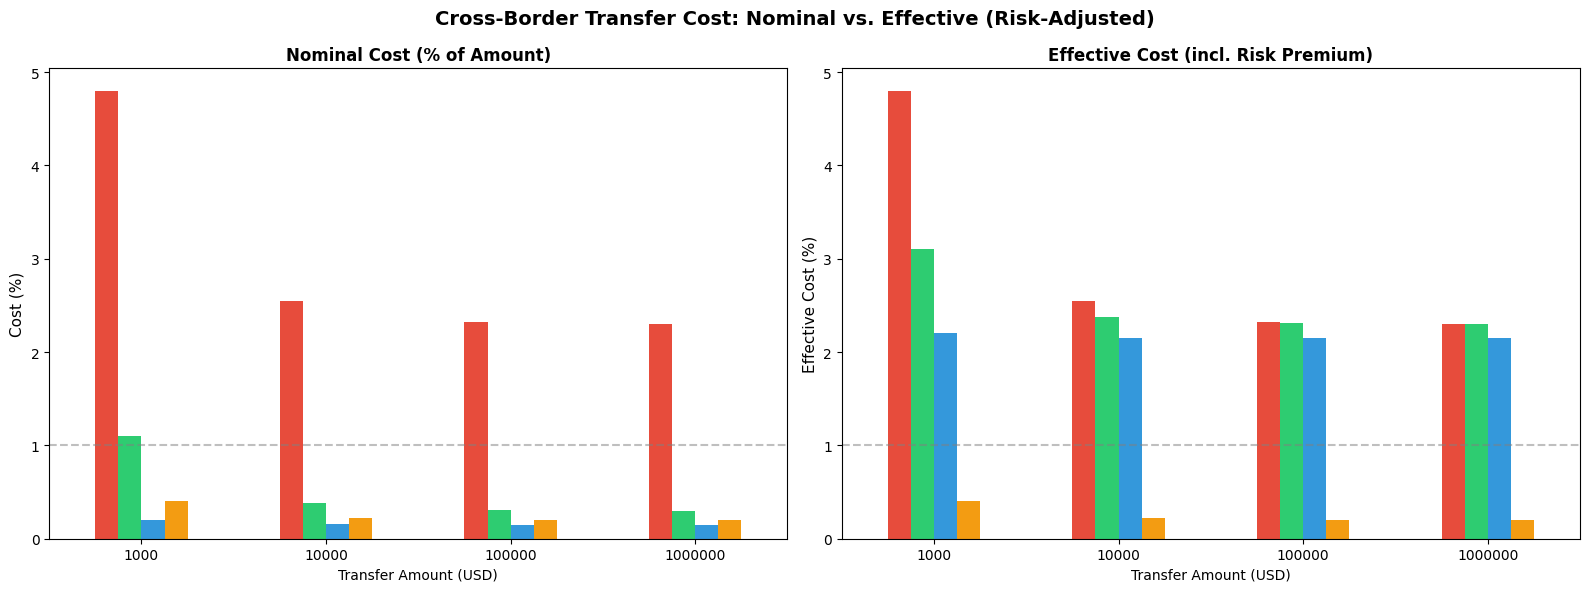


detail about transfer $1,000
        label  nominal_cost_usd  risk_cost_usd  effective_cost_usd  time_hours  intermediaries
        SWIFT              48.0            0.0                48.0       72.00               3
 mBridge CBDC               4.0            0.0                 4.0        0.01               1
USDC (ERC-20)              11.0           20.0                31.0        0.08               0
USDC (TRC-20)               2.0           20.0                22.0        0.02               0

 Effective Cost：
  • SWIFT effective:  $48.00 (4.80%)
  • mBridge CBDC:   $4.00 (0.40%)  ← lowerst risk, cost control最低风险，成本可控
  • USDC (ERC-20):  $31.00 (3.10%) 2% deppeging
  • USDC (TRC-20):  $22.00 (2.20%)  2% deppeging

✅ CBDC effective cost lower than USDC ERC-20  $27.00，
   lower than USDC TRC-20 $18.00。


In [26]:
import pandas as pd
import matplotlib.pyplot as plt

def transfer_cost(method, amount_usd):

    specs = {
        'SWIFT': {
            'fixed': 25, 'pct': 0.015, 'time_h': 72, 'hops': 3,
            'fx_spread': 0.008, 'risk_premium': 0.000,
            'label': 'SWIFT'
        },
        'mBridge_CBDC': {
            'fixed': 2, 'pct': 0.001, 'time_h': 0.01, 'hops': 1,
            'fx_spread': 0.001, 'risk_premium': 0.000,
            'label': 'mBridge CBDC'
        },
        'USDC_ERC20': {
            'fixed': 8, 'pct': 0.001, 'time_h': 0.08, 'hops': 0,
            'fx_spread': 0.002, 'risk_premium': 0.020,  # 2% deppeging risk
            'label': 'USDC (ERC-20)'
        },
        'USDC_TRC20': {
            'fixed': 0.5, 'pct': 0.0005, 'time_h': 0.02, 'hops': 0,
            'fx_spread': 0.001, 'risk_premium': 0.020,  # deppeging
            'label': 'USDC (TRC-20)'
        }
    }
    s = specs[method]

    # Nominal fees = Fixed fees + Transaction volume × (Percentage fees + Exchange rate difference)
    nominal_fee = s['fixed'] + amount_usd * (s['pct'] + s['fx_spread'])

    # Risk cost = Trading volume × Risk premium
    risk_cost = amount_usd * s['risk_premium']

    # Effective cost = Nominal cost + Risk cost
    effective_fee = nominal_fee + risk_cost

    return {
        'method': method,
        'label': s['label'],
        'amount': amount_usd,
        'nominal_cost_usd': nominal_fee,
        'risk_cost_usd': risk_cost,
        'effective_cost_usd': effective_fee,
        'time_hours': s['time_h'],
        'intermediaries': s['hops'],
        'nominal_pct': (nominal_fee / amount_usd) * 100,
        'effective_pct': (effective_fee / amount_usd) * 100
    }

# amount: retails / whole sales
amounts = [1_000, 10_000, 100_000, 1_000_000]
methods = ['SWIFT', 'mBridge_CBDC', 'USDC_ERC20', 'USDC_TRC20']
results = [transfer_cost(m, a) for a in amounts for m in methods]
df = pd.DataFrame(results)

#nominal and effctive
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_alpha(0.0)

# nominal coast
pivot_nominal = df.pivot(index='amount', columns='method', values='nominal_pct')
# SWIFT(red), CBDC(green), ERC20(blue), TRC20(orange)
colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']
pivot_nominal.plot(kind='bar', ax=ax1, color=colors, legend=False)
ax1.patch.set_alpha(0.0)
ax1.set_title('Nominal Cost (% of Amount)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Cost (%)', fontsize=11)
ax1.set_xlabel('Transfer Amount (USD)')
ax1.axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='1% threshold')
#ax1.legend(loc='upper left')
ax1.tick_params(axis='x', rotation=0)

# effective
pivot_effective = df.pivot(index='amount', columns='method', values='effective_pct')
pivot_effective.plot(kind='bar', ax=ax2, color=colors, legend=False)
ax2.patch.set_alpha(0.0)
ax2.set_title('Effective Cost (incl. Risk Premium)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Effective Cost (%)', fontsize=11)
ax2.set_xlabel('Transfer Amount (USD)')
ax2.axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='1% threshold')
#ax2.legend(loc='upper left')
ax2.tick_params(axis='x', rotation=0)

plt.suptitle('Cross-Border Transfer Cost: Nominal vs. Effective (Risk-Adjusted)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# print compare base $1,000

print("\n" + "="*80)
print("detail about transfer $1,000")
print("="*80)
print(df[df['amount']==1000][['label', 'nominal_cost_usd', 'risk_cost_usd',
                               'effective_cost_usd', 'time_hours', 'intermediaries']].to_string(index=False))


print("\n Effective Cost：")
cbdc_row = df[(df['amount']==1000) & (df['method']=='mBridge_CBDC')].iloc[0]
usdc_erc = df[(df['amount']==1000) & (df['method']=='USDC_ERC20')].iloc[0]
usdc_trc = df[(df['amount']==1000) & (df['method']=='USDC_TRC20')].iloc[0]
swift_row = df[(df['amount']==1000) & (df['method']=='SWIFT')].iloc[0]

print(f"  • SWIFT effective:  ${swift_row['effective_cost_usd']:.2f} ({swift_row['effective_pct']:.2f}%)")
print(f"  • mBridge CBDC:   ${cbdc_row['effective_cost_usd']:.2f} ({cbdc_row['effective_pct']:.2f}%)  ← lowerst risk, cost control最低风险，成本可控")
print(f"  • USDC (ERC-20):  ${usdc_erc['effective_cost_usd']:.2f} ({usdc_erc['effective_pct']:.2f}%) 2% deppeging")
print(f"  • USDC (TRC-20):  ${usdc_trc['effective_cost_usd']:.2f} ({usdc_trc['effective_pct']:.2f}%)  2% deppeging")
print(f"\n✅ CBDC effective cost lower than USDC ERC-20  ${(usdc_erc['effective_cost_usd'] - cbdc_row['effective_cost_usd']):.2f}，")
print(f"   lower than USDC TRC-20 ${(usdc_trc['effective_cost_usd'] - cbdc_row['effective_cost_usd']):.2f}。")
print("="*80)

In [ ]:
"""
Cross-Border Payment Cost Calculator
Compares Legacy (SWIFT), Stablecoin, and CBDC (mBridge) architectures.
"""

from dataclasses import dataclass
from typing import Optional
from enum import Enum

class RailType(Enum):
    SWIFT_CORRESPONDENT = "swift"
    STABLECOIN = "stablecoin"
    CBDC_BRIDGE = "cbdc_bridge"

@dataclass
class TransactionProfile:
    amount_usd: float
    origin_currency: str
    destination_currency: str
    corridor_risk_premium: float = 0.0  # Emerging market premium (0.0–0.05)

@dataclass
class CostStructure:
    rail: RailType
    name: str

    # Fixed costs (USD)
    messaging_fee: float
    compliance_screening: float

    # Variable costs (% of amount)
    fx_spread_bps: float          # Basis points (1 bps = 0.01%)
    intermediary_markup_bps: float
    liquidity_cost_bps: float     # Slippage / opportunity cost

    # Time parameters
    settlement_hours: float
    nostro_vostro_tie_up: float   # Capital locked in transit (% annualized, converted to tx cost)

    # 2026-specific parameters
    reserve_yield_pass_through_bps: float = 0.0  # Interest-bearing benefit
    mbridge_automation_discount: float = 0.0       # CBDC atomic settlement savings

class CrossBorderCalculator:
    # Assumptions for capital cost
    ANNUAL_COST_OF_CAPITAL = 0.05  # 5% WACC for bank capital tied up

    def calculate(self, tx: TransactionProfile, rail: CostStructure) -> dict:
        amount = tx.amount_usd

        # Fixed costs
        total_fixed = rail.messaging_fee + rail.compliance_screening

        # Variable costs in USD
        fx_cost = amount * (rail.fx_spread_bps / 10000)
        intermediary_cost = amount * (rail.intermediary_markup_bps / 10000)
        liquidity_cost = amount * (rail.liquidity_cost_bps / 10000)

        # Nostro/Vostro capital cost (pro-rated by settlement time)
        # Assume capital is locked for full settlement period
        capital_cost = amount * rail.nostro_vostro_tie_up * (rail.settlement_hours / (365 * 24)) * self.ANNUAL_COST_OF_CAPITAL

        # Apply corridor risk premium to FX and liquidity only
        risk_adjustment = amount * tx.corridor_risk_premium * 0.01  # Simplified

        # 2026 adjustments
        yield_benefit = amount * (rail.reserve_yield_pass_through_bps / 10000) if rail.reserve_yield_pass_through_bps else 0
        automation_saving = amount * rail.mbridge_automation_discount

        total_cost = (total_fixed + fx_cost + intermediary_cost + liquidity_cost +
                     capital_cost + risk_adjustment - yield_benefit - automation_saving)

        cost_percentage = (total_cost / amount) * 100 if amount > 0 else 0

        # Speed score (normalized)
        speed_score = min(100, max(0, 100 - (rail.settlement_hours * 2)))

        return {
            'rail': rail.name,
            'amount_usd': amount,
            'total_cost_usd': round(total_cost, 2),
            'cost_as_percent': round(cost_percentage, 3),
            'settlement_time_hours': rail.settlement_hours,
            'speed_score': round(speed_score, 1),
            'cost_breakdown': {
                'fixed_fees': round(total_fixed, 2),
                'fx_spread': round(fx_cost, 2),
                'intermediary': round(intermediary_cost, 2),
                'liquidity_slippage': round(liquidity_cost, 2),
                'capital_tie_up': round(capital_cost, 2),
                'risk_premium': round(risk_adjustment, 2),
                'yield_benefit': round(-yield_benefit, 2),
                'automation_saving': round(-automation_saving, 2)
            },
            'efficiency_rating': self._efficiency_rating(cost_percentage, rail.settlement_hours)
        }

    def _efficiency_rating(self, cost_pct: float, hours: float) -> str:
        if cost_pct < 0.5 and hours <= 1: return "A+ (Optimal)"
        if cost_pct < 1.5 and hours <= 24: return "A (Excellent)"
        if cost_pct < 3.0 and hours <= 72: return "B (Good)"
        if cost_pct < 5.0: return "C (Acceptable)"
        return "D (Legacy)"

def demo():
    calc = CrossBorderCalculator()

    # Transaction: $1,000 retail remittance USA → Mexico (high volume corridor)
    tx_retail = TransactionProfile(
        amount_usd=1000,
        origin_currency="USD",
        destination_currency="MXN",
        corridor_risk_premium=0.01  # 1% EM premium
    )

    # Transaction: $1,000,000 wholesale B2B USA → Brazil
    tx_wholesale = TransactionProfile(
        amount_usd=1_000_000,
        origin_currency="USD",
        destination_currency="BRL",
        corridor_risk_premium=0.02  # 2% premium
    )

    rails = {
        'swift': CostStructure(
            rail=RailType.SWIFT_CORRESPONDENT,
            name="SWIFT Correspondent Banking",
            messaging_fee=25.0,
            compliance_screening=50.0,
            fx_spread_bps=250,        # 2.5%
            intermediary_markup_bps=75,
            liquidity_cost_bps=30,
            settlement_hours=72,
            nostro_vostro_tie_up=0.15,
            reserve_yield_pass_through_bps=0,
            mbridge_automation_discount=0
        ),
        'stablecoin': CostStructure(
            rail=RailType.STABLECOIN,
            name="USDC on Ethereum → Off-ramp",
            messaging_fee=2.0,         # Gas approximated
            compliance_screening=15.0, # Chainalysis/KYT
            fx_spread_bps=50,          # DEX + off-ramp spread
            intermediary_markup_bps=100, # Exchange fee + spread
            liquidity_cost_bps=20,     # Slippage on $1M
            settlement_hours=0.25,     # 15 min avg
            nostro_vostro_tie_up=0.0,  # No pre-funded accounts
            reserve_yield_pass_through_bps=0,  # Assuming non-interest bearing
            mbridge_automation_discount=0
        ),
        'cbdc': CostStructure(
            rail=RailType.CBDC_BRIDGE,
            name="mBridge / CBDC Atomic Settlement",
            messaging_fee=0.0,
            compliance_screening=5.0,  # Embedded KYC
            fx_spread_bps=15,          # Policy rate, tight spread
            intermediary_markup_bps=10, # Bank fee minimal
            liquidity_cost_bps=5,      # PvP eliminates Herstatt risk
            settlement_hours=0.01,     # Real-time (~36 seconds)
            nostro_vostro_tie_up=0.0,  # No pre-funding needed
            reserve_yield_pass_through_bps=0,
            mbridge_automation_discount=0.001  # 0.1% automation benefit
        )
    }

    print("=" * 80)
    print("CROSS-BORDER COST CALCULATOR — 2026 FRAMEWORK")
    print("=" * 80)

    for tx_name, tx in [("RETAIL ($1,000 USD→MXN)", tx_retail),
                        ("WHOLESALE ($1M USD→BRL)", tx_wholesale)]:
        print(f"\n{'='*40}")
        print(f"SCENARIO: {tx_name}")
        print(f"{'='*40}")

        for rail_key in ['swift', 'stablecoin', 'cbdc']:
            result = calc.calculate(tx, rails[rail_key])
            print(f"\n{result['rail']}")
            print(f"  Total Cost: ${result['total_cost_usd']:,.2f} ({result['cost_as_percent']:.3f}%)")
            print(f"  Settlement: {result['settlement_time_hours']:.2f} hours")
            print(f"  Rating: {result['efficiency_rating']}")
            print(f"  Breakdown: {result['cost_breakdown']}")

if __name__ == "__main__":
    demo()

CROSS-BORDER COST CALCULATOR — 2026 FRAMEWORK

SCENARIO: RETAIL ($1,000 USD→MXN)

SWIFT Correspondent Banking
  Total Cost: $110.66 (11.066%)
  Settlement: 72.00 hours
  Rating: D (Legacy)
  Breakdown: {'fixed_fees': 75.0, 'fx_spread': 25.0, 'intermediary': 7.5, 'liquidity_slippage': 3.0, 'capital_tie_up': 0.06, 'risk_premium': 0.1, 'yield_benefit': 0, 'automation_saving': 0}

USDC on Ethereum → Off-ramp
  Total Cost: $34.10 (3.410%)
  Settlement: 0.25 hours
  Rating: C (Acceptable)
  Breakdown: {'fixed_fees': 17.0, 'fx_spread': 5.0, 'intermediary': 10.0, 'liquidity_slippage': 2.0, 'capital_tie_up': 0.0, 'risk_premium': 0.1, 'yield_benefit': 0, 'automation_saving': 0}

mBridge / CBDC Atomic Settlement
  Total Cost: $7.10 (0.710%)
  Settlement: 0.01 hours
  Rating: A (Excellent)
  Breakdown: {'fixed_fees': 5.0, 'fx_spread': 1.5, 'intermediary': 1.0, 'liquidity_slippage': 0.5, 'capital_tie_up': 0.0, 'risk_premium': 0.1, 'yield_benefit': 0, 'automation_saving': -1.0}

SCENARIO: WHOLESALE 

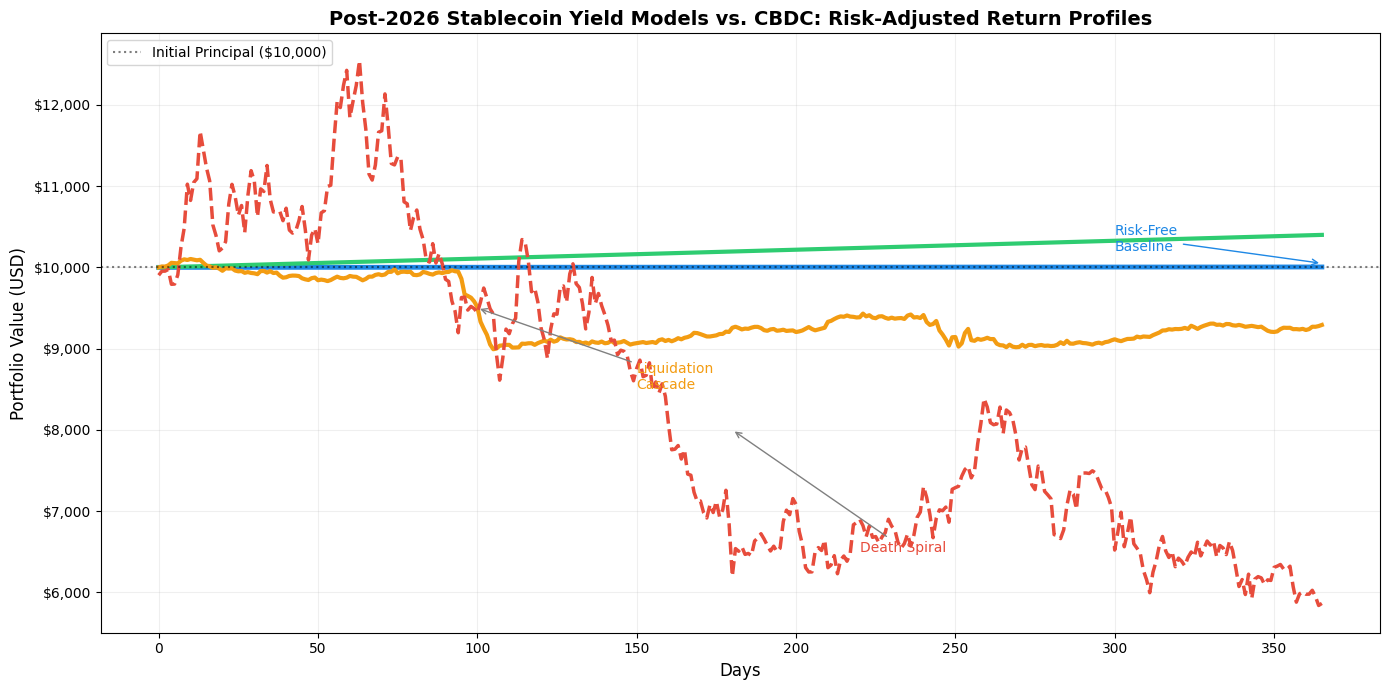

one year comparesion (Principal $10,000)
CBDC (0.05%):            $10,005.00  |  Interest Rate Yield: $5.00
Pass-through (4%):       $10,400.00  | Interest Rate Yield: $400.00
CDP (5% + volatility):         $9,291.70  |  Interest Rate Yield: $-708.30
Rebase (speculation):           $5,864.29  |  Interest Rate Yield: $-4135.71


In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# param
DAYS = 365
INITIAL = 10000  # initial 10,000 usd/yuan
np.random.seed(42)

# --- Model 0: CBDC (e-CNY) ---
# rate 0.05%
rate_cbdc = 0.0005  # 0.05%
daily_cbdc = (1 + rate_cbdc) ** (1/365) - 1
cumulative_cbdc = INITIAL * (1 + daily_cbdc) ** np.arange(DAYS + 1)

# --- Model 1: Pass-through (Circle Yield) ---
# T-Bill 4.5% - fee 0.5% = 4.0% annal
rate_pass = 0.04
daily_pass = (1 + rate_pass) ** (1/365) - 1
cumulative_pass = INITIAL * (1 + daily_pass) ** np.arange(DAYS + 1)

# --- Model 2: CDP (DAI-style / sDAI) ---
# base return 5%, but includes liquidation impact.
rate_cdp = 0.05
daily_cdp_base = (1 + rate_cdp) ** (1/365) - 1
cumulative_cdp = [INITIAL]
for day in range(1, DAYS + 1):
    ret = daily_cdp_base
    # simulate: A liquidation crash (-15%) occurred around day 100.
    if 95 <= day <= 105:
        ret += np.random.normal(-0.005, 0.01)
    # simulate: A governance shock (-10%) occurred around day 250.
    elif 240 <= day <= 255:
        ret += np.random.normal(-0.003, 0.008)
    else:
        ret += np.random.normal(0, 0.002)
    new_val = cumulative_cdp[-1] * (1 + ret)
    cumulative_cdp.append(max(new_val, INITIAL * 0.5))
cumulative_cdp = np.array(cumulative_cdp)

# --- Model 3: Rebase (AMPL-style) ---
#High volatility, with long-term net returns approaching zero.
mu = 0.01
sigma = 0.45
dt = 1/365
returns_rebase = np.random.normal(
    (mu - 0.5 * sigma**2) * dt,
    sigma * np.sqrt(dt),
    DAYS + 1
)
for day in [60, 180, 300]:
    if day < len(returns_rebase):
        returns_rebase[day] -= 0.08
        returns_rebase[day+1] += 0.04
cumulative_rebase = INITIAL * np.exp(np.cumsum(returns_rebase))

# plt
fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_alpha(0.0)
ax.patch.set_alpha(0.0)

# Color schemes: CBDC (dark blue), Pass-through (green), CDP (orange), Rebase (red)
ax.plot(cumulative_cbdc, color='#1E88E5', linewidth=3.5)
ax.plot(cumulative_pass, color='#2ecc71', linewidth=3)
ax.plot(cumulative_cdp, color='#f39c12', linewidth=3)
ax.plot(cumulative_rebase, color='#e74c3c', linewidth=2.5, linestyle='--')

# shock
ax.annotate('Liquidation\nCascade', xy=(100, 9500), xytext=(150, 8500),
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=10, color='#f39c12')
ax.annotate('Death Spiral', xy=(180, 8000), xytext=(220, 6500),
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=10, color='#e74c3c')
# risk free cbdc
ax.annotate('Risk-Free\nBaseline', xy=(365, 10050), xytext=(300, 10200),
            arrowprops=dict(arrowstyle='->', color='#1E88E5'), fontsize=10, color='#1E88E5')

ax.set_title('Post-2026 Stablecoin Yield Models vs. CBDC: Risk-Adjusted Return Profiles',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Days', fontsize=12)
ax.set_ylabel('Portfolio Value (USD)', fontsize=12)
ax.axhline(y=INITIAL, color='black', linestyle=':', alpha=0.5, label='Initial Principal ($10,000)')
ax.grid(True, alpha=0.2)
ax.legend(loc='upper left', fontsize=10)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

plt.tight_layout()
plt.show()


print("=" * 80)
print("one year comparesion (Principal $10,000)")
print("=" * 80)
print(f"CBDC (0.05%):            ${cumulative_cbdc[-1]:,.2f}  |  Interest Rate Yield: ${cumulative_cbdc[-1]-INITIAL:.2f}")
print(f"Pass-through (4%):       ${cumulative_pass[-1]:,.2f}  | Interest Rate Yield: ${cumulative_pass[-1]-INITIAL:.2f}")
print(f"CDP (5% + volatility):         ${cumulative_cdp[-1]:,.2f}  |  Interest Rate Yield: ${cumulative_cdp[-1]-INITIAL:.2f}")
print(f"Rebase (speculation):           ${cumulative_rebase[-1]:,.2f}  |  Interest Rate Yield: ${cumulative_rebase[-1]-INITIAL:.2f}")
print("=" * 80)